# ถ้าอุบัติเหตุร้ายแรง ร้ายแรงเพราะปัจจัยอะไร (Severity Factors)

**โจทย์:** ระบุปัจจัยที่ทำให้อุบัติเหตุกลายเป็นอุบัติเหตุร้ายแรง

**ร้ายแรง** หมายถึง มีผู้เสียชีวิตหรือผู้บาดเจ็บสาหัสอย่างน้อย 1 คน

**ต่างจาก notebook `severity_map` อย่างไร:** เล่มนั้นถามว่า "จะร้ายแรงไหม" จึงใช้ได้เฉพาะข้อมูลที่รู้ก่อนเกิดเหตุ เล่มนี้ถามว่า "ร้ายแรงเพราะอะไร" จึงใช้ข้อมูลที่บรรยายตัวเหตุได้ทั้งหมด เช่น มีรถอะไรอยู่ในเหตุ และชนกันแบบไหน ห้ามใช้อย่างเดียวคือจำนวนผู้เสียชีวิตและผู้บาดเจ็บ เพราะนั่นคือคำตอบ

**โมเดลรับอะไร** (หนึ่งแถวคืออุบัติเหตุ 1 ครั้ง)

| ชื่อ | type | ความหมาย |
|---|---|---|
| ปัจจัย 27 ตัว เช่น `มีจักรยานยนต์`, `กลางคืน`, `ชนประสานงา` | int (0 หรือ 1) | 1 คือเหตุนี้มีปัจจัยนั้น |
| `province` | category (78 ค่า) | จังหวัด ใช้คุมความต่างของพื้นที่ |
| `road_type` | category (3 ค่า) | ประเภทถนน ใช้คุมความต่างของหน่วยงานที่บันทึก |

**โมเดลตอบอะไร**

| คำตอบ | type | ตัวอย่าง |
|---|---|---|
| โอกาสร้ายแรงของเหตุนั้น | float (0.0 ถึง 1.0) | 0.71 คือ 71% |
| ปัจจัยแต่ละตัวเพิ่มโอกาสร้ายแรงกี่เท่า (odds ratio) | ตาราง: ชื่อปัจจัย (str), ค่า (float) | `มีจักรยานยนต์` 6.0 เท่า |
| เหตุนี้ร้ายแรงเพราะปัจจัยไหน | ตาราง: ชื่อปัจจัย (str), แรงผลัก (float, จุด %) | `มีจักรยานยนต์` +56 จุด |

**สิ่งที่จะทำ:** อ่านข้อมูล → สำรวจ → คลีน → ดูข้อมูล → สร้างปัจจัย → แบ่งข้อมูล → เลือกโมเดล → ประเมิน → ตอบโจทย์

รันเซลล์จากบนลงล่าง ข้อมูลดิบอยู่ใน `data/datagov/` ส่วนไฟล์ที่ notebook นี้สร้างจะอยู่ใน `data/explore_idea/severity_factors/`

## 1. อ่านข้อมูล
ใช้ข้อมูลอุบัติเหตุทั้งประเทศปี 2563–2569 (ค.ศ. 2020–2026) ปี 2569 มีถึงเดือนตุลาคม

ไม่ใช้ปี 2562 (2019) เพราะไฟล์ปีนั้นไม่มีคอลัมน์ผู้บาดเจ็บสาหัส จึงสร้างคำตอบ "ร้ายแรง" ไม่ได้

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from matplotlib import font_manager
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss, confusion_matrix
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

pd.set_option("display.max_rows", 40)
pd.set_option("display.max_columns", 12)

In [2]:
# เลือกฟอนต์ที่แสดงภาษาไทยในกราฟได้
# ถ้าเครื่องไม่มีฟอนต์เหล่านี้ กราฟยังวาดได้ แต่ตัวอักษรไทยอาจเป็นกล่องสี่เหลี่ยม
installed_fonts = []
for font in font_manager.fontManager.ttflist:
    installed_fonts.append(font.name)

for font_name in ["Thonburi", "Tahoma", "Sarabun", "Noto Sans Thai"]:
    if font_name in installed_fonts:
        plt.rcParams["font.family"] = font_name
        break

In [3]:
# หาโฟลเดอร์โปรเจกต์ โดยเดินขึ้นไปทีละชั้นจนเจอโฟลเดอร์ data/datagov
project_dir = Path.cwd().resolve()
while not (project_dir / "data" / "datagov").is_dir():
    if project_dir == project_dir.parent:
        raise FileNotFoundError("ไม่พบโฟลเดอร์ data/datagov")
    project_dir = project_dir.parent

raw_dir = project_dir / "data" / "datagov"
idea_dir = project_dir / "data" / "explore_idea" / "severity_factors"
clean_dir = idea_dir / "clean"
feature_dir = idea_dir / "features"
model_dir = idea_dir / "model"
result_dir = idea_dir / "results"

for folder in [clean_dir, feature_dir, model_dir, result_dir]:
    folder.mkdir(parents=True, exist_ok=True)

years = [2020, 2021, 2022, 2023, 2024, 2025, 2026]

In [4]:
# ปี 2026 ตั้งชื่อคอลัมน์บางตัวต่างจากปีอื่น จึงเปลี่ยนชื่อให้ตรงกันก่อนรวม
rename_2026 = {
    "บริเวณที่เกิดเหตุ/ลักษณะทาง": "บริเวณที่เกิดเหตุ",
    "ลักษณะการเกิดอุบัติเหตุ": "ลักษณะการเกิดเหตุ",
    "จำนวนรถที่เกิดเหตุ(รวมคันที่1)": "รถที่เกิดเหตุ",
    "รถบรรทุกมากกว่า6ล้อไม่เกิน10ล้อ": "รถบรรทุกไม่เกิน10ล้อ",
    "รถบรรทุกมากกว่า10ล้อ(รถพ่วง)": "รถบรรทุกมากกว่า10ล้อ",
    "จำนวนผู้เสียชีวิต": "ผู้เสียชีวิต",
    "จำนวนผู้บาดเจ็บสาหัส": "ผู้บาดเจ็บสาหัส",
    "จำนวนผู้บาดเจ็บเล็กน้อย": "ผู้บาดเจ็บเล็กน้อย",
}

frames = []
for year in years:
    table = pd.read_csv(raw_dir / f"accident{year}.csv", dtype=str, encoding="utf-8-sig")
    if year == 2026:
        table = table.rename(columns=rename_2026)
    table["file_year"] = year
    frames.append(table)
    print(year, "จำนวนแถว:", len(table))

raw = pd.concat(frames, ignore_index=True)
print("รวมทั้งหมด:", len(raw), "แถว |", raw.shape[1], "คอลัมน์")

2020 จำนวนแถว: 21239
2021 จำนวนแถว: 20062
2022 จำนวนแถว: 20566


2023 จำนวนแถว: 23841
2024 จำนวนแถว: 23952
2025 จำนวนแถว: 23715


2026 จำนวนแถว: 18448
รวมทั้งหมด: 151823 แถว | 44 คอลัมน์


In [5]:
# เก็บเฉพาะคอลัมน์ที่ใช้ และเปลี่ยนชื่อให้เขียนโค้ดง่าย
column_names = {
    "วันที่เกิดเหตุ": "date_text",
    "เวลา": "time_text",
    "ACC_CODE": "acc_code",
    "สายทางหน่วยงาน": "road_type",
    "รหัสสายทาง": "route_code",
    "จังหวัด": "province",
    "รถคันที่1": "vehicle",
    "บริเวณที่เกิดเหตุ": "area",
    "ลักษณะการเกิดเหตุ": "crash_type_text",
    "มูลเหตุสันนิษฐาน": "cause_text",
    "สภาพอากาศ": "weather",
    "LATITUDE": "lat",
    "LONGITUDE": "lon",
    "รถที่เกิดเหตุ": "n_vehicles",
    "รถจักรยานยนต์": "n_motorcycle",
    "รถบรรทุก6ล้อ": "n_truck6",
    "รถบรรทุกไม่เกิน10ล้อ": "n_truck10",
    "รถบรรทุกมากกว่า10ล้อ": "n_truck10plus",
    "คนเดินเท้า": "n_pedestrian",
    "ผู้เสียชีวิต": "deaths",
    "ผู้บาดเจ็บสาหัส": "serious_injuries",
    "ผู้บาดเจ็บเล็กน้อย": "minor_injuries",
}
selected_columns = ["file_year"] + list(column_names.keys())
data = raw[selected_columns].rename(columns=column_names)
data.head(3)

,file_year,date_text,time_text,acc_code,road_type,route_code,...,n_truck10,n_truck10plus,n_pedestrian,deaths,serious_injuries,minor_injuries
0,2020,1/1/2020,0:05,3785916,ทางหลวง,4225,...,0,0,1,0,1,0
1,2020,1/1/2020,0:05,3786314,ทางหลวง,3473,...,0,0,0,0,1,0
2,2020,1/1/2020,0:15,575019,ทางหลวงชนบท,นภ.3038,...,0,0,0,1,0,0


**คอลัมน์ที่เพิ่มจาก notebook `severity_map`**
- `n_vehicles`: จำนวนรถทั้งหมดในเหตุ
- `n_motorcycle`, `n_truck6`, `n_truck10`, `n_truck10plus`: จำนวนรถแต่ละประเภทในเหตุ
- `n_pedestrian`: จำนวนคนเดินเท้าในเหตุ
- `cause_text`: มูลเหตุสันนิษฐานที่เจ้าหน้าที่บันทึก

## 2. สำรวจข้อมูลดิบ
ก่อนคลีน ต้องรู้ก่อนว่าข้อมูลมีปัญหาอะไรบ้าง ดู 4 เรื่อง คือ ค่าว่าง รูปแบบวันที่และเวลา เหตุที่บันทึกซ้ำ และจำนวนหมวดหมู่ของแต่ละปี

In [6]:
# ค่าว่างของแต่ละคอลัมน์ คิดเป็น %
missing_percent = data.isna().mean() * 100
missing_percent.round(1).sort_values(ascending=False)

acc_code            12.2
area                 8.5
crash_type_text      5.6
cause_text           1.9
vehicle              1.5
province             1.3
weather              0.6
lat                  0.6
lon                  0.6
n_truck6             0.0
serious_injuries     0.0
deaths               0.0
n_pedestrian         0.0
n_truck10plus        0.0
n_truck10            0.0
file_year            0.0
n_motorcycle         0.0
n_vehicles           0.0
date_text            0.0
route_code           0.0
road_type            0.0
time_text            0.0
minor_injuries       0.0
dtype: float64

In [7]:
# ดูตัวอย่างวันที่และเวลาของแต่ละปี จะเห็นว่าเขียนไม่เหมือนกัน
for year in years:
    rows = data.loc[data["file_year"].eq(year)]
    example = rows.iloc[500]
    print(year, "| วันที่:", example["date_text"], "| เวลา:", example["time_text"])

2020 | วันที่: 1/3/2020 | เวลา: 14:50
2021 | วันที่: 1/3/2021 | เวลา: 0:10
2022 | วันที่: 02/01/2022 | เวลา: 19:30
2023 | วันที่: 1/2/2023 | เวลา: 20:00
2024 | วันที่: 45294 | เวลา: 0.145833333
2025 | วันที่: 45660 | เวลา: 13:30
2026 | วันที่: 3/1/2026 | เวลา: 4:30


In [8]:
# รหัสเหตุ (acc_code) ที่ซ้ำกันในปีเดียวกัน แปลว่าเหตุเดียวถูกบันทึกมากกว่า 1 แถว
has_code = data["acc_code"].notna()
repeated_code = has_code & data.duplicated(["file_year", "acc_code"])
print("จำนวนแถวที่รหัสเหตุซ้ำ แยกตามปี")
print(repeated_code.groupby(data["file_year"]).sum())

จำนวนแถวที่รหัสเหตุซ้ำ แยกตามปี
file_year
2020       0
2021       0
2022       0
2023    1702
2024       0
2025       0
2026       0
dtype: int64


In [9]:
# จำนวนคำที่ไม่ซ้ำกันของ "ลักษณะการชน" และ "มูลเหตุ" ในแต่ละปี
unique_count = data.groupby("file_year")[["crash_type_text", "cause_text"]].nunique()
unique_count.columns = ["ลักษณะการชน (จำนวนแบบ)", "มูลเหตุ (จำนวนแบบ)"]
unique_count

,ลักษณะการชน (จำนวนแบบ),มูลเหตุ (จำนวนแบบ)
file_year,,
2020,11,38
2021,10,38
2022,11,48
2023,152,103
2024,10,49
2025,10,47
2026,10,46


**สิ่งที่พบ**
- **ค่าว่าง:** `acc_code` ว่างทั้งปี 2026 เพราะไฟล์ปีนั้นไม่มีรหัสเหตุ ส่วน `area` (ลักษณะถนน) และ `crash_type_text` (ลักษณะการชน) ว่างประมาณ 5–9% จำนวนรถและคนเดินเท้าไม่มีค่าว่าง
- **วันที่:** ปี 2020–2023 เขียนแบบ เดือน/วัน/ปี ปี 2024–2025 เป็นเลขลำดับวันของ Excel เช่น 45540 และปี 2026 เขียนแบบ วัน/เดือน/ปี
- **เวลา:** ปี 2024 เป็นเศษส่วนของวัน เช่น 0.5 หมายถึงเที่ยงวัน ปีอื่นเขียนแบบ ชั่วโมง:นาที
- **เหตุซ้ำ:** ปี 2023 มีรหัสเหตุซ้ำประมาณ 1,700 แถว
- **หมวดหมู่ไม่เหมือนกันทุกปี:** ปี 2023 เขียนลักษณะการชนถึง 152 แบบ ส่วนปีอื่นมีประมาณ 10 แบบ มูลเหตุก็มีหลายสิบแบบและสะกดไม่เหมือนกัน จึงต้องจัดกลุ่มใหม่ด้วยคำสำคัญ ไม่อย่างนั้นโมเดลจะมองว่าเป็นคนละเรื่องกัน

## 3. คลีนข้อมูล
แก้ทีละเรื่องตามที่พบในขั้นสำรวจ แล้วบันทึกผลเป็นไฟล์ใน `clean/`

### 3.1 วันที่
แปลงแยกปี เพราะแต่ละปีเขียนไม่เหมือนกัน

In [10]:
data["date"] = pd.NaT
for year in years:
    rows = data["file_year"].eq(year)
    values = data.loc[rows, "date_text"]
    if year in [2024, 2025]:
        # เลขลำดับวันของ Excel นับจากวันที่ 30 ธ.ค. 1899
        numbers = pd.to_numeric(values, errors="coerce")
        dates = pd.to_datetime(numbers, unit="D", origin="1899-12-30", errors="coerce")
    elif year == 2026:
        dates = pd.to_datetime(values, format="%d/%m/%Y", errors="coerce")
    else:
        dates = pd.to_datetime(values, format="%m/%d/%Y", errors="coerce")
    data.loc[rows, "date"] = dates

data["date"] = pd.to_datetime(data["date"])

# วันที่ต้องอ่านได้ และต้องอยู่ในปีเดียวกับไฟล์
valid_date = data["date"].notna() & data["date"].dt.year.eq(data["file_year"])
print("แถวที่วันที่ใช้ไม่ได้:", int((~valid_date).sum()))
data = data.loc[valid_date].copy()

แถวที่วันที่ใช้ไม่ได้: 1


### 3.2 เวลา
เก็บเฉพาะ "ชั่วโมง" (0–23) สำหรับปี 2024 ที่เป็นเศษส่วนของวัน ต้องแปลงเป็นนาทีแล้ว **ปัดเศษ** ก่อน

เหตุผล: เวลา 01:00 ถูกเก็บเป็น 0.041666667 ถ้าเอาไปคูณ 24 ตรง ๆ บางแถวจะได้ 0.99999 แล้วกลายเป็นชั่วโมง 0 ซึ่งผิด

In [11]:
def time_to_hour(text):
    if pd.isna(text):
        return np.nan
    if ":" in text:
        # แบบ ชั่วโมง:นาที เช่น "14:30" ได้ 14
        return int(text.split(":")[0])
    # แบบเศษส่วนของวัน เช่น "0.5" ได้ 720 นาที คือ 12 นาฬิกา
    minutes = round(float(text) * 24 * 60)
    hour = minutes // 60
    if hour > 23:
        hour = 23
    return hour


data["hour"] = data["time_text"].apply(time_to_hour)
print("ชั่วโมงต่ำสุด:", data["hour"].min(), "| สูงสุด:", data["hour"].max(), "| ค่าว่าง:", int(data["hour"].isna().sum()))

ชั่วโมงต่ำสุด: 0 | สูงสุด: 23 | ค่าว่าง: 0


### 3.3 เหตุที่บันทึกซ้ำ
ถ้ารหัสเหตุซ้ำกันในปีเดียวกัน เก็บไว้แถวเดียว แล้วลบแถวที่เหมือนกันทุกช่องอีกรอบ (สำหรับปี 2026 ที่ไม่มีรหัสเหตุ)

In [12]:
rows_before = len(data)

has_code = data["acc_code"].notna()
repeated_code = has_code & data.duplicated(["file_year", "acc_code"])
data = data.loc[~repeated_code].copy()

data = data.drop_duplicates().copy()

print("ก่อนลบ:", rows_before, "แถว | หลังลบ:", len(data), "แถว | ลบไป:", rows_before - len(data))

ก่อนลบ: 151822 แถว | หลังลบ: 150097 แถว | ลบไป: 1725


### 3.4 ตัวเลข และคำตอบ "ร้ายแรง"
แปลงข้อความเป็นตัวเลข แล้วสร้างคอลัมน์ `severe`
- `severe = 1` เมื่อมีผู้เสียชีวิตหรือผู้บาดเจ็บสาหัสอย่างน้อย 1 คน
- `severe = 0` ในกรณีอื่น

In [13]:
number_columns = ["deaths", "serious_injuries", "minor_injuries", "lat", "lon",
                  "n_vehicles", "n_motorcycle", "n_truck6", "n_truck10", "n_truck10plus", "n_pedestrian"]
for column in number_columns:
    data[column] = pd.to_numeric(data[column], errors="coerce")

count_columns = ["deaths", "serious_injuries", "minor_injuries",
                 "n_vehicles", "n_motorcycle", "n_truck6", "n_truck10", "n_truck10plus", "n_pedestrian"]
print("ค่าว่างของคอลัมน์จำนวน:")
print(data[count_columns].isna().sum())

data["severe"] = ((data["deaths"] + data["serious_injuries"]) > 0).astype(int)
print("สัดส่วนเหตุร้ายแรง:", round(data["severe"].mean() * 100, 1), "%")

ค่าว่างของคอลัมน์จำนวน:
deaths              0
serious_injuries    0
minor_injuries      0
n_vehicles          0
n_motorcycle        0
n_truck6            0
n_truck10           0
n_truck10plus       0
n_pedestrian        0
dtype: int64
สัดส่วนเหตุร้ายแรง: 18.5 %


In [14]:
# พิกัดที่อยู่นอกกรอบประเทศไทยถือว่ากรอกผิด เปลี่ยนเป็นค่าว่าง แต่ยังเก็บแถวไว้
in_thailand = data["lat"].between(5.5, 20.6) & data["lon"].between(97.2, 105.8)
print("พิกัดที่ว่างหรืออยู่นอกประเทศไทย:", int((~in_thailand).sum()), "แถว")
data.loc[~in_thailand, ["lat", "lon"]] = np.nan

พิกัดที่ว่างหรืออยู่นอกประเทศไทย: 869 แถว


### 3.5 ข้อมูลแบบหมวดหมู่
- ตัดช่องว่างหัวท้าย และเติมค่าว่างด้วยคำว่า "ไม่ระบุ"
- จังหวัด "อยุธยา" กับ "พระนครศรีอยุธยา" คือจังหวัดเดียวกัน จึงรวมเป็นชื่อเดียว
- ลักษณะถนน ลักษณะการชน และมูลเหตุ มีหลายสิบถึงร้อยกว่าแบบ จึงจัดเป็นกลุ่มใหญ่ไม่กี่กลุ่มด้วยคำสำคัญ

In [15]:
data["province"] = data["province"].str.strip().replace({"อยุธยา": "พระนครศรีอยุธยา"}).fillna("ไม่ระบุ")
data["weather"] = data["weather"].str.strip().fillna("ไม่ระบุ")
data["road_type"] = data["road_type"].str.strip().fillna("ไม่ระบุ")
data["vehicle"] = data["vehicle"].str.strip().fillna("ไม่ระบุ")

In [16]:
# ลักษณะถนนเขียนเป็น "รูปร่างถนน+ความลาดชัน" เช่น "ทางโค้งกว้าง+ที่ลาดชัน"
def find_road_shape(text):
    if pd.isna(text):
        return "ไม่ระบุ"
    first_part = text.split("+")[0]
    if "โค้ง" in first_part:
        return "ทางโค้ง"
    if "ทางตรง" in first_part:
        return "ทางตรง"
    for word in ["แยก", "วงเวียน", "ทางร่วม", "กลับรถ", "Ramps"]:
        if word in first_part:
            return "ทางแยก"
    if "เชื่อม" in first_part or "เข้า" in first_part:
        return "ทางเชื่อม"
    return "อื่นๆ"


def find_road_slope(text):
    if pd.isna(text) or "+" not in text:
        return "ไม่ระบุ"
    second_part = text.split("+", 1)[1]
    if "ไม่มีความลาดชัน" in second_part or "ที่ราบ" in second_part:
        return "ทางราบ"
    return "ลาดชัน"


data["road_shape"] = data["area"].apply(find_road_shape)
data["road_slope"] = data["area"].apply(find_road_slope)
print(data["road_shape"].value_counts())
print()
print(data["road_slope"].value_counts())

road_shape
ทางตรง       107703
ทางโค้ง       22895
ไม่ระบุ       12784
ทางแยก         3789
ทางเชื่อม      2371
อื่นๆ           555
Name: count, dtype: int64

road_slope
ทางราบ     123438
ไม่ระบุ     19023
ลาดชัน       7636
Name: count, dtype: int64


In [17]:
# จัดลักษณะการชนเป็นกลุ่มใหญ่
def find_crash_type(text):
    if pd.isna(text):
        return "ไม่ระบุ"
    if "คนเดินเท้า" in text:
        return "ชนคนเดินเท้า"
    if "ชนท้าย" in text:
        return "ชนท้าย"
    for word in ["พลิกคว่ำ", "ตกถนน", "เสียหลัก", "เสียการควบคุม", "ล้มเอง"]:
        if word in text:
            return "พลิกคว่ำ/ตกถนน"
    for word in ["ตรงกันข้าม", "ประสานงา", "ฝั่งตรงข้าม"]:
        if word in text:
            return "ชนประสานงา"
    for word in ["สิ่งกีดขวาง", "ชนเกาะ", "ชนป้าย", "จอด"]:
        if word in text:
            return "ชนสิ่งกีดขวาง"
    for word in ["ทางแยก", "เลี้ยว", "ด้านข้าง", "เฉี่ยว", "ทางตรงชน"]:
        if word in text:
            return "ชนด้านข้าง/ทางแยก"
    return "อื่นๆ"


data["crash_type"] = data["crash_type_text"].apply(find_crash_type)
data["crash_type"].value_counts()

crash_type
พลิกคว่ำ/ตกถนน       76140
ชนท้าย               46453
ไม่ระบุ               7635
ชนประสานงา            6611
ชนสิ่งกีดขวาง         6580
อื่นๆ                 3048
ชนด้านข้าง/ทางแยก     2100
ชนคนเดินเท้า          1530
Name: count, dtype: int64

In [18]:
# จัดมูลเหตุสันนิษฐานเป็นกลุ่มใหญ่
def find_cause(text):
    if pd.isna(text):
        return "ไม่ระบุ"
    if "ขับรถเร็ว" in text:
        return "ขับรถเร็ว"
    if "ตัดหน้า" in text:
        return "ตัดหน้ากระชั้นชิด"
    if "หลับใน" in text:
        return "หลับใน"
    if "เมาสุรา" in text or "มึนเมา" in text:
        return "เมาสุรา"
    if "ฝ่าฝืนสัญญาณไฟ" in text:
        return "ฝ่าฝืนสัญญาณไฟ"
    if "แซง" in text:
        return "แซงผิดกฎหมาย"
    if "ย้อนศร" in text:
        return "ขับย้อนศร"
    if "ยาง" in text:
        return "ยางแตก"
    for word in ["อุปกรณ์ยานพาหนะ", "ห้ามล้อ", "เบรคชำรุด"]:
        if word in text:
            return "อุปกรณ์รถบกพร่อง"
    if "ถนนลื่น" in text:
        return "ถนนลื่น"
    return "อื่นๆ"


data["cause"] = data["cause_text"].apply(find_cause)
data["cause"].value_counts()

cause
ขับรถเร็ว            106392
ตัดหน้ากระชั้นชิด     11605
หลับใน                10419
อื่นๆ                  6743
ยางแตก                 2711
อุปกรณ์รถบกพร่อง       2708
ไม่ระบุ                2654
เมาสุรา                2090
ถนนลื่น                1998
ฝ่าฝืนสัญญาณไฟ         1531
แซงผิดกฎหมาย            628
ขับย้อนศร               618
Name: count, dtype: int64

### 3.6 บันทึกข้อมูลที่คลีนแล้ว
หนึ่งแถวคือหนึ่งเหตุ

In [19]:
clean_columns = ["file_year", "date", "hour", "province", "road_type", "vehicle",
                 "weather", "road_shape", "road_slope", "crash_type", "cause",
                 "n_vehicles", "n_motorcycle", "n_truck6", "n_truck10", "n_truck10plus", "n_pedestrian",
                 "lat", "lon", "deaths", "serious_injuries", "minor_injuries", "severe"]
clean = data[clean_columns].rename(columns={"file_year": "year"}).reset_index(drop=True)

clean_path = clean_dir / "accidents_clean.csv"
clean.to_csv(clean_path, index=False, encoding="utf-8-sig")
print("บันทึกแล้ว:", clean_path.relative_to(project_dir), "|", len(clean), "แถว")
clean.head(3)

บันทึกแล้ว: data/explore_idea/severity_factors/clean/accidents_clean.csv | 150097 แถว


,year,date,hour,province,road_type,vehicle,...,lat,lon,deaths,serious_injuries,minor_injuries,severe
0,2020,2020-01-01,0,กระบี่,ทางหลวง,คนเดินเท้า,...,8.008887,99.390674,0,1,0,1
1,2020,2020-01-01,0,นครสวรรค์,ทางหลวง,รถจักรยานยนต์,...,15.650940,99.478422,0,1,0,1
2,2020,2020-01-01,0,หนองบัวลำภู,ทางหลวงชนบท,รถจักรยานยนต์,...,17.191475,102.454305,1,0,0,1


## 4. ดูข้อมูล
ดู 4 เรื่องที่มีผลกับการสร้างปัจจัยในขั้นถัดไป

### 4.1 เหตุร้ายแรงในแต่ละปี

In [20]:
by_year = clean.groupby("year")["severe"].agg(["size", "mean"])
by_year.columns = ["จำนวนเหตุ", "สัดส่วนร้ายแรง"]
by_year.round(3)

,จำนวนเหตุ,สัดส่วนร้ายแรง
year,,
2020,21238,0.220
2021,20062,0.203
2022,20566,0.181
2023,22139,0.176
2024,23952,0.182
2025,23715,0.169
2026,18425,0.168


**อ่านตาราง:** สัดส่วนเหตุร้ายแรงลดลงจาก 22.0% ในปี 2020 เหลือ 16.8% ในปี 2026 ภาพรวมทุกปีอยู่ที่ 18.5% เหตุไม่ร้ายแรงจึงมีมากกว่าประมาณ 4 เท่า

### 4.2 กับดักของคอลัมน์ "รถคันที่ 1"
ข้อมูลมีทั้ง "รถคันที่ 1" (ประเภทรถคันแรกที่บันทึก) และ "จำนวนรถแต่ละประเภทในเหตุ" สองอย่างนี้ให้ภาพไม่เท่ากัน

In [21]:
first_is_motorcycle = clean["vehicle"].eq("รถจักรยานยนต์")
any_motorcycle = clean["n_motorcycle"] > 0
hidden_motorcycle = any_motorcycle & ~first_is_motorcycle

print("รถคันที่ 1 เป็นจักรยานยนต์:", round(first_is_motorcycle.mean() * 100, 1), "% ของเหตุทั้งหมด")
print("มีจักรยานยนต์อยู่ในเหตุ:", round(any_motorcycle.mean() * 100, 1), "% ของเหตุทั้งหมด")
print()
print("เหตุที่มีจักรยานยนต์ แต่ไม่ได้เป็นรถคันที่ 1:", int(hidden_motorcycle.sum()), "เหตุ")
print("สัดส่วนร้ายแรงของเหตุกลุ่มนี้:", round(clean.loc[hidden_motorcycle, "severe"].mean() * 100, 1), "%")
print("สัดส่วนร้ายแรงของเหตุที่ไม่มีจักรยานยนต์เลย:", round(clean.loc[~any_motorcycle, "severe"].mean() * 100, 1), "%")

รถคันที่ 1 เป็นจักรยานยนต์: 14.7 % ของเหตุทั้งหมด
มีจักรยานยนต์อยู่ในเหตุ: 21.4 % ของเหตุทั้งหมด

เหตุที่มีจักรยานยนต์ แต่ไม่ได้เป็นรถคันที่ 1: 10145 เหตุ
สัดส่วนร้ายแรงของเหตุกลุ่มนี้: 45.0 %
สัดส่วนร้ายแรงของเหตุที่ไม่มีจักรยานยนต์เลย: 11.1 %


**อ่านผล:** จักรยานยนต์เป็นรถคันที่ 1 เพียง 14.7% ของเหตุ แต่อยู่ในเหตุจริง 21.4% เหตุที่จักรยานยนต์เป็นคู่กรณีมี 10,145 เหตุ และร้ายแรงถึง 45.0% เทียบกับ 11.1% ของเหตุที่ไม่มีจักรยานยนต์ ถ้าดูแค่รถคันที่ 1 จะมองไม่เห็นเหตุกลุ่มนี้เลย

notebook นี้จึงใช้ "มีรถประเภทนี้อยู่ในเหตุไหม" แทน "รถคันที่ 1 คืออะไร"

### 4.3 มูลเหตุสันนิษฐาน

In [22]:
by_cause = clean.groupby("cause")["severe"].agg(["size", "mean"])
by_cause.columns = ["จำนวนเหตุ", "สัดส่วนร้ายแรง"]
by_cause["สัดส่วนของเหตุทั้งหมด"] = by_cause["จำนวนเหตุ"] / len(clean)
by_cause.sort_values("จำนวนเหตุ", ascending=False).round(3)

,จำนวนเหตุ,สัดส่วนร้ายแรง,สัดส่วนของเหตุทั้งหมด
cause,,,
ขับรถเร็ว,106392,0.173,0.709
ตัดหน้ากระชั้นชิด,11605,0.341,0.077
หลับใน,10419,0.159,0.069
อื่นๆ,6743,0.204,0.045
ยางแตก,2711,0.048,0.018
อุปกรณ์รถบกพร่อง,2708,0.098,0.018
ไม่ระบุ,2654,0.013,0.018
เมาสุรา,2090,0.343,0.014
ถนนลื่น,1998,0.085,0.013


**อ่านตาราง:** เจ้าหน้าที่บันทึกมูลเหตุว่า "ขับรถเร็ว" ถึง 70.9% ของเหตุ และเหตุกลุ่มนี้ร้ายแรง 17.3% ซึ่งใกล้กับค่าเฉลี่ย 18.5% คอลัมน์นี้จึงเกือบเป็นค่าเดียวกันทุกแถว และแยกเหตุร้ายแรงได้น้อย

มูลเหตุที่ดูร้ายแรงสูงคือ ขับย้อนศร แซงผิดกฎหมาย เมาสุรา ฝ่าฝืนสัญญาณไฟ และตัดหน้ากระชั้นชิด แต่ยังสรุปไม่ได้ ต้องดูข้อ 4.4 ก่อน

### 4.4 ตัวเลขดิบหลอกตาได้
เหตุที่บันทึกว่า "เมาสุรา" ร้ายแรง 34% ซึ่งสูงกว่าค่าเฉลี่ยเกือบสองเท่า แต่ถ้าแยกดูตามว่ามีจักรยานยนต์ในเหตุไหม ภาพจะเปลี่ยนไป

In [23]:
check = pd.DataFrame({
    "มีจักรยานยนต์": any_motorcycle,
    "เมาสุรา": clean["cause"].eq("เมาสุรา"),
    "severe": clean["severe"],
})
drunk_table = check.groupby(["มีจักรยานยนต์", "เมาสุรา"])["severe"].agg(["size", "mean"])
drunk_table.columns = ["จำนวนเหตุ", "สัดส่วนร้ายแรง"]
print(drunk_table.round(3))
print()
print("เหตุเมาสุราที่มีจักรยานยนต์:", round(check.loc[check["เมาสุรา"], "มีจักรยานยนต์"].mean() * 100, 1), "%")
print("เหตุทั่วไปที่มีจักรยานยนต์:", round(check.loc[~check["เมาสุรา"], "มีจักรยานยนต์"].mean() * 100, 1), "%")

                       จำนวนเหตุ  สัดส่วนร้ายแรง
มีจักรยานยนต์ เมาสุรา                           
False         False       116998           0.110
              True           914           0.211
True          False        31009           0.459
              True          1176           0.445

เหตุเมาสุราที่มีจักรยานยนต์: 56.3 %
เหตุทั่วไปที่มีจักรยานยนต์: 21.0 %


**อ่านตาราง:** เหตุเมาสุรา 56.3% มีจักรยานยนต์อยู่ด้วย ขณะที่เหตุทั่วไปมีเพียง 21.0%

ในกลุ่มที่มีจักรยานยนต์ เหตุเมาสุราร้ายแรง 44.5% ซึ่งไม่ต่างจากเหตุที่ไม่เมา (45.9%) ตัวเลข 34% ของเหตุเมาสุราจึงสูงเพราะมีจักรยานยนต์ปนอยู่มาก ไม่ได้มาจากการเมาอย่างเดียว

ในกลุ่มที่ไม่มีจักรยานยนต์ เหตุเมาสุราร้ายแรง 21.1% สูงกว่าเหตุที่ไม่เมา (11.0%) แต่มีเพียง 914 เหตุ ผลของการเมาจึงมีอยู่ แต่ไม่ชัดเท่าที่ตัวเลข 34% บอก

📌 เรื่องนี้เรียกว่า **confounding** คือปัจจัยสองตัวมาด้วยกัน จนแยกไม่ออกว่าตัวไหนมีผลจริง ถ้าดูทีละปัจจัยจะสรุปผิด

notebook นี้จึงไม่ตอบโจทย์ด้วยตารางสัดส่วนดิบ แต่ใช้โมเดลที่ดูทุกปัจจัยพร้อมกัน เพื่อแยกผลของแต่ละปัจจัยออกจากกัน

## 5. สร้างปัจจัย
แปลงข้อมูลเป็นปัจจัยแบบ "มี" (1) หรือ "ไม่มี" (0) รวม 27 ตัว แบ่งเป็น 5 กลุ่ม

| กลุ่ม | ปัจจัย |
|---|---|
| ใครอยู่ในเหตุ | มีคนเดินเท้า, มีจักรยานยนต์, มีรถบรรทุกใหญ่ (6 ล้อขึ้นไป), จักรยานยนต์กับรถบรรทุกใหญ่, รถ 2 คัน, รถ 3 คันขึ้นไป |
| ชนกันแบบไหน | ชนประสานงา, ชนท้าย, ชนสิ่งกีดขวาง, ชนด้านข้าง/ทางแยก |
| มูลเหตุสันนิษฐาน | ตัดหน้ากระชั้นชิด, หลับใน, เมาสุรา, ฝ่าฝืนสัญญาณไฟ, แซงผิดกฎหมาย, ขับย้อนศร, ยางแตก, อุปกรณ์รถบกพร่อง, ถนนลื่น |
| เมื่อไร | กลางคืน (19:00–04:59), ปีใหม่, สงกรานต์, เสาร์อาทิตย์ |
| สภาพแวดล้อม | ฝนตก, ทางโค้ง, ทางแยก, ทางลาดชัน |

**กรณีอ้างอิง** คือเหตุที่ปัจจัยทุกตัวเป็น 0 ได้แก่ รถคันเดียวพลิกคว่ำหรือตกถนน มูลเหตุขับรถเร็ว ตอนกลางวันของวันธรรมดา อากาศไม่มีฝน บนทางตรงทางราบ ผลของปัจจัยทุกตัวจะเทียบกับกรณีนี้

**ไม่ใช้เป็นปัจจัย:** จำนวนผู้เสียชีวิตและผู้บาดเจ็บ เพราะเป็นคำตอบ

In [24]:
month = clean["date"].dt.month
day = clean["date"].dt.day
heavy_truck_count = clean["n_truck6"] + clean["n_truck10"] + clean["n_truck10plus"]

factors = pd.DataFrame(index=clean.index)

# กลุ่มที่ 1: ใครอยู่ในเหตุ
factors["มีคนเดินเท้า"] = (clean["n_pedestrian"] > 0) | clean["crash_type"].eq("ชนคนเดินเท้า") | clean["vehicle"].eq("คนเดินเท้า")
factors["มีจักรยานยนต์"] = clean["n_motorcycle"] > 0
factors["มีรถบรรทุกใหญ่"] = heavy_truck_count > 0
factors["จักรยานยนต์กับรถบรรทุกใหญ่"] = factors["มีจักรยานยนต์"] & factors["มีรถบรรทุกใหญ่"]
factors["รถ 2 คัน"] = clean["n_vehicles"].eq(2)
factors["รถ 3 คันขึ้นไป"] = clean["n_vehicles"] >= 3

# กลุ่มที่ 2: ชนกันแบบไหน
factors["ชนประสานงา"] = clean["crash_type"].eq("ชนประสานงา")
factors["ชนท้าย"] = clean["crash_type"].eq("ชนท้าย")
factors["ชนสิ่งกีดขวาง"] = clean["crash_type"].eq("ชนสิ่งกีดขวาง")
factors["ชนด้านข้าง/ทางแยก"] = clean["crash_type"].eq("ชนด้านข้าง/ทางแยก")

# กลุ่มที่ 3: มูลเหตุสันนิษฐาน
for cause_name in ["ตัดหน้ากระชั้นชิด", "หลับใน", "เมาสุรา", "ฝ่าฝืนสัญญาณไฟ", "แซงผิดกฎหมาย",
                   "ขับย้อนศร", "ยางแตก", "อุปกรณ์รถบกพร่อง", "ถนนลื่น"]:
    factors[cause_name] = clean["cause"].eq(cause_name)

# กลุ่มที่ 4: เมื่อไร
factors["กลางคืน"] = (clean["hour"] >= 19) | (clean["hour"] <= 4)
factors["ปีใหม่"] = (month.eq(12) & (day >= 27)) | (month.eq(1) & (day <= 4))
factors["สงกรานต์"] = month.eq(4) & day.between(10, 17)
factors["เสาร์อาทิตย์"] = clean["date"].dt.day_of_week >= 5

# กลุ่มที่ 5: สภาพแวดล้อม
factors["ฝนตก"] = clean["weather"].eq("ฝนตก")
factors["ทางโค้ง"] = clean["road_shape"].eq("ทางโค้ง")
factors["ทางแยก"] = clean["road_shape"].eq("ทางแยก")
factors["ทางลาดชัน"] = clean["road_slope"].eq("ลาดชัน")

# เปลี่ยน True/False เป็น 1/0
factors = factors.astype(int)

factor_names = list(factors.columns)
print("จำนวนปัจจัย:", len(factor_names))
factors.head(3)

จำนวนปัจจัย: 27


,มีคนเดินเท้า,มีจักรยานยนต์,มีรถบรรทุกใหญ่,จักรยานยนต์กับรถบรรทุกใหญ่,รถ 2 คัน,รถ 3 คันขึ้นไป,...,สงกรานต์,เสาร์อาทิตย์,ฝนตก,ทางโค้ง,ทางแยก,ทางลาดชัน
0,1,0,0,0,0,0,...,0,0,0,1,0,0
1,0,1,0,0,1,0,...,0,0,0,0,0,0
2,0,1,0,0,0,0,...,0,0,0,0,1,0


### 5.1 เหตุร้ายแรงกับเหตุไม่ร้ายแรง มีปัจจัยต่างกันตรงไหน
ดูว่าปัจจัยแต่ละตัวพบในเหตุร้ายแรงกี่ % และพบในเหตุไม่ร้ายแรงกี่ %

In [25]:
severe_rows = factors.loc[clean["severe"].eq(1)]
other_rows = factors.loc[clean["severe"].eq(0)]

profile = pd.DataFrame({
    "พบในเหตุร้ายแรง (%)": severe_rows.mean() * 100,
    "พบในเหตุไม่ร้ายแรง (%)": other_rows.mean() * 100,
})
profile["ต่างกัน (เท่า)"] = profile["พบในเหตุร้ายแรง (%)"] / profile["พบในเหตุไม่ร้ายแรง (%)"]
profile = profile.sort_values("ต่างกัน (เท่า)", ascending=False)
profile.round(2)

,พบในเหตุร้ายแรง (%),พบในเหตุไม่ร้ายแรง (%),ต่างกัน (เท่า)
มีคนเดินเท้า,4.55,0.35,12.81
จักรยานยนต์กับรถบรรทุกใหญ่,8.28,0.77,10.71
ขับย้อนศร,1.25,0.22,5.62
มีจักรยานยนต์,53.06,14.24,3.73
ชนประสานงา,10.88,2.93,3.71
แซงผิดกฎหมาย,0.88,0.31,2.81
เมาสุรา,2.57,1.12,2.29
ตัดหน้ากระชั้นชิด,14.22,6.25,2.27
ฝ่าฝืนสัญญาณไฟ,1.82,0.84,2.17
รถ 2 คัน,51.98,30.28,1.72


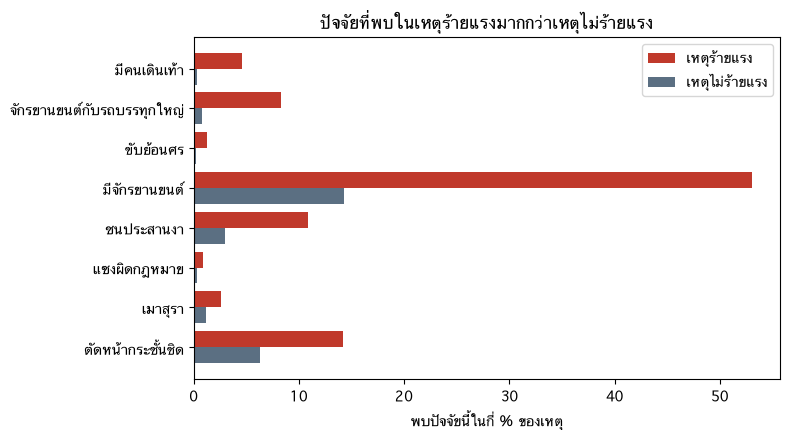

In [26]:
# วาดเฉพาะ 8 ปัจจัยที่ต่างกันมากที่สุด
top_profile = profile.head(8).iloc[::-1]
positions = np.arange(len(top_profile))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(positions + 0.2, top_profile["พบในเหตุร้ายแรง (%)"], height=0.4, color="#c0392b", label="เหตุร้ายแรง")
ax.barh(positions - 0.2, top_profile["พบในเหตุไม่ร้ายแรง (%)"], height=0.4, color="#5b6f82", label="เหตุไม่ร้ายแรง")
ax.set_yticks(positions)
ax.set_yticklabels(top_profile.index)
ax.set(xlabel="พบปัจจัยนี้ในกี่ % ของเหตุ", title="ปัจจัยที่พบในเหตุร้ายแรงมากกว่าเหตุไม่ร้ายแรง")
ax.legend()
plt.tight_layout()
plt.show()

**อ่านกราฟ:** จักรยานยนต์อยู่ในเหตุร้ายแรง 53.1% แต่อยู่ในเหตุไม่ร้ายแรงเพียง 14.2% เป็นความต่างที่ใหญ่ที่สุดเมื่อนับเป็นจำนวนเหตุ

คนเดินเท้าต่างกันมากที่สุดเมื่อนับเป็นจำนวนเท่า คือ 4.6% กับ 0.4% หรือ 12.8 เท่า แต่พบน้อย ส่วนการชนประสานงาพบ 10.9% กับ 2.9%

ตารางนี้ยังเป็นตัวเลขดิบ จึงยังมีปัญหา confounding แบบข้อ 4.4 ขั้นถัดไปจะใช้โมเดลแยกผลของแต่ละปัจจัย

### 5.2 บันทึกตารางปัจจัย
เพิ่มจังหวัดและประเภทถนนเข้าไปด้วย สองคอลัมน์นี้ไม่ได้เป็นปัจจัยที่จะรายงาน แต่ใส่ให้โมเดลเพื่อ **คุมความต่างของพื้นที่**

เหตุผล: แต่ละจังหวัดและแต่ละหน่วยงานมีสัดส่วนเหตุร้ายแรงต่างกันมาก ส่วนหนึ่งมาจากการบันทึกเหตุเล็กน้อยไม่เท่ากัน ถ้าไม่คุมไว้ ผลของพื้นที่จะปนเข้าไปในปัจจัยอื่น

In [27]:
place_columns = ["province", "road_type"]
model_columns = factor_names + place_columns

features = factors.copy()
features["province"] = clean["province"]
features["road_type"] = clean["road_type"]
features["year"] = clean["year"]
features["severe"] = clean["severe"]
print(features.shape)

(150097, 31)


## 6. แบ่งข้อมูล
แบ่งตามเวลา เหมือน notebook `severity_map` เพื่อให้เทียบกันได้
- **Train:** ปี 2020–2023 ใช้ฝึกโมเดล
- **Validation:** ปี 2024 ใช้เลือกโมเดล
- **Test:** ปี 2025–ต.ค. 2026 ใช้ประเมินครั้งสุดท้าย โมเดลไม่เคยเห็นข้อมูลชุดนี้

In [28]:
def find_split(year):
    if year <= 2023:
        return "train"
    if year == 2024:
        return "validation"
    return "test"


features["split"] = features["year"].apply(find_split)

feature_path = feature_dir / "accidents_factors.csv"
features.to_csv(feature_path, index=False, encoding="utf-8-sig")
print("บันทึกแล้ว:", feature_path.relative_to(project_dir))

train = features.loc[features["split"].eq("train")]
validation = features.loc[features["split"].eq("validation")]
test = features.loc[features["split"].eq("test")]

for name, part in [("Train", train), ("Validation", validation), ("Test", test)]:
    print(name, "| จำนวนเหตุ:", len(part), "| ร้ายแรง:", round(part["severe"].mean() * 100, 1), "%")

บันทึกแล้ว: data/explore_idea/severity_factors/features/accidents_factors.csv
Train | จำนวนเหตุ: 84005 | ร้ายแรง: 19.5 %
Validation | จำนวนเหตุ: 23952 | ร้ายแรง: 18.2 %
Test | จำนวนเหตุ: 42140 | ร้ายแรง: 16.9 %


## 7. วิธีวัดผล
โจทย์นี้ต้องวัด 2 ชั้น

**ชั้นที่ 1: โมเดลเข้ากับความจริงแค่ไหน** ถ้าโมเดลทำนายไม่ได้ ตัวเลขปัจจัยที่อ่านจากโมเดลก็เชื่อไม่ได้
- **PR-AUC** (ตัวหลัก): เมื่อโมเดลชี้ว่าร้ายแรง ชี้ถูกแค่ไหน ค่าของการเดาสุ่มเท่ากับสัดส่วนเหตุร้ายแรง
- **ROC-AUC:** เรียงลำดับเหตุร้ายแรงไว้เหนือเหตุไม่ร้ายแรงได้ถูกแค่ไหน ค่า 0.5 คือเดาสุ่ม
- **Brier score:** เปอร์เซ็นต์ที่ทำนายคลาดเคลื่อนเท่าไร ยิ่งต่ำยิ่งดี

**ชั้นที่ 2: ตัวเลขของแต่ละปัจจัยเชื่อได้ไหม** (ทำในหัวข้อ 10)
- **คงที่ข้ามช่วงปี:** ฝึกโมเดลแยกสองช่วงปี แล้วดูว่าได้ค่าใกล้กันไหม
- **ช่วงความไม่แน่นอน:** สุ่มข้อมูลซ้ำ 100 รอบ แล้วดูว่าค่าแกว่งแค่ไหน

**Baseline:** ใช้สัดส่วนเหตุร้ายแรงของ "มีจักรยานยนต์" กับ "ไม่มีจักรยานยนต์" จากข้อมูล Train โมเดลต้องชนะวิธีง่าย ๆ นี้ให้ได้

In [29]:
def evaluate(name, y_true, y_prob):
    return {
        "วิธี": name,
        "PR-AUC": average_precision_score(y_true, y_prob),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "Brier": brier_score_loss(y_true, y_prob),
    }


def baseline_predict(train_part, target_part):
    # สัดส่วนร้ายแรงของกลุ่มที่มีและไม่มีจักรยานยนต์ จากข้อมูลฝึก
    rate_by_group = train_part.groupby("มีจักรยานยนต์")["severe"].mean()
    return target_part["มีจักรยานยนต์"].map(rate_by_group).values


validation_baseline = baseline_predict(train, validation)
pd.DataFrame([evaluate("Baseline", validation["severe"], validation_baseline)]).round(3)

,วิธี,PR-AUC,ROC-AUC,Brier
0,Baseline,0.317,0.685,0.131


## 8. เลือกโมเดล
ลอง 4 โมเดลกับปัจจัยชุดเดียวกัน แล้ววัดผลบน Validation (ปี 2024)

ทุกโมเดลใช้ขั้นเตรียมข้อมูลเดียวกัน คือปัจจัย 27 ตัวส่งเข้าโมเดลตรง ๆ เพราะเป็น 0/1 อยู่แล้ว ส่วนจังหวัดและประเภทถนนแปลงด้วย `OneHotEncoder`

In [30]:
def make_prepare():
    place_step = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    return ColumnTransformer([
        ("factor", "passthrough", factor_names),
        ("place", place_step, place_columns),
    ])


estimators = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, min_samples_leaf=20, n_jobs=-1, random_state=42),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=42),
}


def build_model(name):
    return make_pipeline(make_prepare(), clone(estimators[name]))

In [31]:
validation_results = [evaluate("Baseline", validation["severe"], validation_baseline)]

for name in estimators:
    model = build_model(name)
    model.fit(train[model_columns], train["severe"])
    probability = model.predict_proba(validation[model_columns])[:, 1]
    validation_results.append(evaluate(name, validation["severe"], probability))

pd.DataFrame(validation_results).round(3)

,วิธี,PR-AUC,ROC-AUC,Brier
0,Baseline,0.317,0.685,0.131
1,Logistic Regression,0.526,0.806,0.115
2,Decision Tree,0.467,0.783,0.117
3,Random Forest,0.565,0.820,0.112
4,Gradient Boosting,0.586,0.826,0.108


**อ่านตาราง:** ทุกโมเดลชนะ Baseline (0.317) Gradient Boosting ได้ PR-AUC สูงสุด (0.586) รองลงมาคือ Random Forest (0.565) และ Logistic Regression (0.526) ส่วน Decision Tree ต่ำสุด (0.467)

**เลือก Logistic Regression** แม้คะแนนจะไม่สูงที่สุด เหตุผลคือโจทย์ถามว่า "ร้ายแรงเพราะปัจจัยอะไร"
- **Logistic Regression** ให้ตัวเลขหนึ่งตัวต่อหนึ่งปัจจัย อ่านได้ตรง ๆ ว่าปัจจัยนี้เพิ่มโอกาสร้ายแรงกี่เท่า
- **Gradient Boosting และ Random Forest** ทำนายแม่นกว่า แต่ข้างในเป็นต้นไม้นับร้อยต้น จึงบอกไม่ได้ว่าปัจจัยแต่ละตัวมีผลเท่าไร

📌 นี่คือการแลกระหว่าง **ความแม่น** กับ **การอธิบายได้** (accuracy vs interpretability) โจทย์ทำนายควรเลือกตัวที่แม่นที่สุด ส่วนโจทย์อธิบายควรเลือกตัวที่อ่านออก

Gradient Boosting จะถูกใช้อีกครั้งในหัวข้อ 10.5 เพื่อตรวจว่าโมเดลสองแบบเห็นปัจจัยสำคัญตรงกันไหม

## 9. ประเมินบน Test
ฝึกโมเดลใหม่ด้วยปี 2020–2024 แล้ววัดผลกับปี 2025–ต.ค. 2026 ที่โมเดลไม่เคยเห็น

In [32]:
train_validation = pd.concat([train, validation])
test_x = test[model_columns]
test_y = test["severe"]

test_model = build_model("Logistic Regression")
test_model.fit(train_validation[model_columns], train_validation["severe"])
test_prob = test_model.predict_proba(test_x)[:, 1]

boosting_model = build_model("Gradient Boosting")
boosting_model.fit(train_validation[model_columns], train_validation["severe"])
boosting_prob = boosting_model.predict_proba(test_x)[:, 1]

same_for_all = np.full(len(test), train_validation["severe"].mean())
test_baseline = baseline_predict(train_validation, test)

test_results = [
    evaluate("ให้ทุกเหตุได้ค่าเฉลี่ยเท่ากัน", test_y, same_for_all),
    evaluate("Baseline (มีจักรยานยนต์ไหม)", test_y, test_baseline),
    evaluate("Logistic Regression (ตัวที่เลือก)", test_y, test_prob),
    evaluate("Gradient Boosting (ไว้เทียบ)", test_y, boosting_prob),
]
pd.DataFrame(test_results).round(3)

,วิธี,PR-AUC,ROC-AUC,Brier
0,ให้ทุกเหตุได้ค่าเฉลี่ยเท่ากัน,0.169,0.500,0.141
1,Baseline (มีจักรยานยนต์ไหม),0.327,0.706,0.119
2,Logistic Regression (ตัวที่เลือก),0.533,0.818,0.105
3,Gradient Boosting (ไว้เทียบ),0.582,0.838,0.100


**อ่านตาราง:** - **ชนะวิธีง่าย ๆ ชัดเจน:** Logistic Regression ได้ PR-AUC 0.533 สูงกว่า Baseline (0.327) และสูงกว่าการให้ค่าเฉลี่ยเท่ากันทุกเหตุ (0.169) ประมาณ 3 เท่า
- **เรียงลำดับได้ดี:** ROC-AUC 0.818 หมายความว่า ถ้าหยิบเหตุร้ายแรงกับเหตุไม่ร้ายแรงมาอย่างละหนึ่งเหตุ โมเดลให้คะแนนเหตุร้ายแรงสูงกว่า 82 คู่จาก 100 คู่
- **ไม่ได้จำข้อมูลปีเก่า:** คะแนนบน Test (0.533) ใกล้กับ Validation (0.526)
- **ราคาของการอ่านออก:** Gradient Boosting ได้ 0.582 สูงกว่า 0.049 นี่คือสิ่งที่ยอมเสียเพื่อให้อ่านผลของแต่ละปัจจัยได้
- **ดีกว่าโมเดลที่ใช้เฉพาะข้อมูลก่อนเกิดเหตุ:** notebook `severity_map` ได้ PR-AUC 0.463 บนช่วงปีเดียวกัน

### 9.1 เปอร์เซ็นต์ที่โมเดลบอก ตรงกับความจริงไหม (Calibration)
แบ่งเหตุใน Test เป็น 10 กลุ่มตามเปอร์เซ็นต์ที่โมเดลทำนาย แล้วเทียบกับสัดส่วนร้ายแรงจริงของแต่ละกลุ่ม

   โมเดลทำนาย (%)  ร้ายแรงจริง (%)
0             1.6              1.4
1             4.4              4.4
2             6.6              6.0
3             8.5              6.7
4            10.3              7.5
5            12.4              9.7
6            15.5             11.9
7            21.6             20.1
8            37.0             38.0
9            64.7             62.9


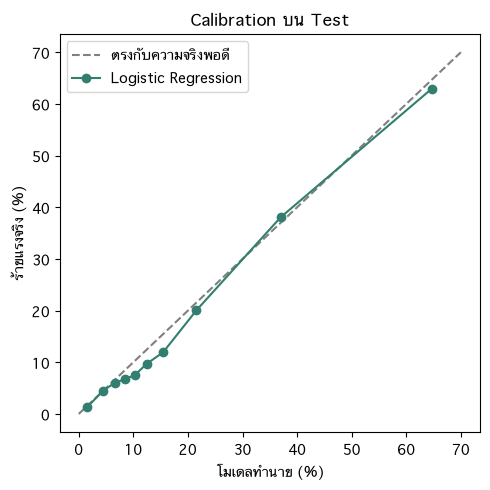

In [33]:
actual_rate, predicted_rate = calibration_curve(test_y, test_prob, n_bins=10, strategy="quantile")

calibration_table = pd.DataFrame({
    "โมเดลทำนาย (%)": predicted_rate * 100,
    "ร้ายแรงจริง (%)": actual_rate * 100,
})
print(calibration_table.round(1))

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 70], [0, 70], linestyle="--", color="gray", label="ตรงกับความจริงพอดี")
ax.plot(predicted_rate * 100, actual_rate * 100, marker="o", color="#327f70", label="Logistic Regression")
ax.set(xlabel="โมเดลทำนาย (%)", ylabel="ร้ายแรงจริง (%)", title="Calibration บน Test")
ax.legend()
plt.tight_layout()
plt.show()

**อ่านกราฟ:** กลุ่มที่โมเดลให้ค่าต่ำสุดและสูงสุดตรงกับความจริง เช่น ทำนาย 64.7% ร้ายแรงจริง 62.9% และทำนาย 37.0% ร้ายแรงจริง 38.0%

กลุ่มกลาง ๆ โมเดลทำนายสูงเกินจริงประมาณ 2–4 จุด เช่น ทำนาย 15.5% ร้ายแรงจริง 11.9% สาเหตุหนึ่งคือสัดส่วนเหตุร้ายแรงลดลงทุกปี จาก 22.0% ในปี 2020 เหลือ 16.9% ในปี 2025–2026 โมเดลที่ฝึกจากปีเก่าจึงคาดสูงไปเล็กน้อย

### 9.2 ถ้าใช้ตัดสินว่า "ร้ายแรง" หรือ "ไม่ร้ายแรง"
ใช้เกณฑ์ 30% เท่ากับ notebook `severity_map` เพื่อให้เทียบกันได้

In [34]:
threshold = 0.30
predicted_severe = (test_prob >= threshold).astype(int)
matrix = confusion_matrix(test_y, predicted_severe)

true_negative = matrix[0, 0]
false_positive = matrix[0, 1]
false_negative = matrix[1, 0]
true_positive = matrix[1, 1]

print("เหตุร้ายแรงจริง:", true_positive + false_negative, "| โมเดลจับได้:", true_positive, "| พลาด:", false_negative)
print("โมเดลบอกว่าร้ายแรง:", true_positive + false_positive, "| ถูก:", true_positive, "| ผิด:", false_positive)
print()
print("Recall (จับเหตุร้ายแรงได้):", round(true_positive / (true_positive + false_negative) * 100, 1), "%")
print("Precision (บอกว่าร้ายแรงแล้วถูก):", round(true_positive / (true_positive + false_positive) * 100, 1), "%")

เหตุร้ายแรงจริง: 7106 | โมเดลจับได้: 4061 | พลาด: 3045
โมเดลบอกว่าร้ายแรง: 7735 | ถูก: 4061 | ผิด: 3674

Recall (จับเหตุร้ายแรงได้): 57.1 %
Precision (บอกว่าร้ายแรงแล้วถูก): 52.5 %


**อ่านผล:** เหตุร้ายแรงจริง 7,106 เหตุ โมเดลจับได้ 4,061 เหตุ (57.1%) และเมื่อโมเดลบอกว่าร้ายแรง จะถูก 52.5%

ดีกว่า notebook `severity_map` ที่จับได้ 36.9% เพราะเล่มนี้รู้ว่ามีรถอะไรอยู่ในเหตุและชนกันแบบไหน

โมเดลยังพลาดเหตุร้ายแรง 43% จึงยังใช้ตัดสินรายเหตุไม่ได้ แต่โจทย์ของเล่มนี้คือระบุปัจจัย ซึ่งต้องการโมเดลที่เข้ากับข้อมูลพอสมควรและอ่านออก

## 10. คำตอบส่วนที่ 1: ปัจจัยไหนทำให้เหตุร้ายแรง
ฝึก Logistic Regression ด้วยข้อมูลทุกปี แล้วอ่าน **odds ratio** ของแต่ละปัจจัย

📌 **Odds ratio** คือ odds ของเหตุร้ายแรงเพิ่มกี่เท่าเมื่อมีปัจจัยนี้ โดยที่ปัจจัยอื่น จังหวัด และประเภทถนนเหมือนเดิม
- มากกว่า 1 คือปัจจัยนี้ทำให้ร้ายแรงขึ้น
- เท่ากับ 1 คือไม่มีผล
- น้อยกว่า 1 คือปัจจัยนี้มากับเหตุที่ร้ายแรงน้อยลง

**Odds** ไม่ใช่เปอร์เซ็นต์ โอกาส 20% คือ odds 0.25 (20 ต่อ 80) ถ้า odds ratio เป็น 6 จะได้ odds 1.5 ซึ่งคือโอกาส 60%

In [35]:
def get_odds_ratios(model):
    # ค่าสัมประสิทธิ์ของปัจจัย 27 ตัวอยู่ลำดับแรก ตามลำดับใน make_prepare
    coefficients = model[-1].coef_[0]
    factor_coefficients = coefficients[:len(factor_names)]
    return pd.Series(np.exp(factor_coefficients), index=factor_names)


all_x = features[model_columns]
all_y = features["severe"]

final_model = build_model("Logistic Regression")
final_model.fit(all_x, all_y)

factor_table = pd.DataFrame({
    "พบในเหตุ (%)": factors.mean() * 100,
    "odds ratio": get_odds_ratios(final_model),
})
factor_table.sort_values("odds ratio", ascending=False).round(2)

,พบในเหตุ (%),odds ratio
มีคนเดินเท้า,1.13,24.49
มีจักรยานยนต์,21.44,6.03
จักรยานยนต์กับรถบรรทุกใหญ่,2.16,2.52
รถ 2 คัน,34.30,2.09
ชนประสานงา,4.40,2.01
รถ 3 คันขึ้นไป,7.83,1.74
กลางคืน,34.30,1.49
ชนสิ่งกีดขวาง,4.38,1.25
หลับใน,6.94,1.22
มีรถบรรทุกใหญ่,20.21,1.21


### 10.1 ปัจจัยคงที่ข้ามช่วงปีไหม
ฝึกโมเดลแยกสองช่วง คือปี 2020–2023 และปี 2024–2026 ถ้าปัจจัยมีผลจริง สองช่วงควรได้ค่าใกล้กัน

In [36]:
early_rows = features["year"] <= 2023
late_rows = features["year"] >= 2024

early_model = build_model("Logistic Regression")
early_model.fit(all_x.loc[early_rows], all_y.loc[early_rows])

late_model = build_model("Logistic Regression")
late_model.fit(all_x.loc[late_rows], all_y.loc[late_rows])

factor_table["ปี 2020–2023"] = get_odds_ratios(early_model)
factor_table["ปี 2024–2026"] = get_odds_ratios(late_model)

### 10.2 ช่วงความไม่แน่นอน
📌 ใช้วิธี **bootstrap** คือสุ่มหยิบเหตุจากข้อมูลเดิมแบบใส่คืน ให้ได้จำนวนเท่าเดิม แล้วฝึกโมเดลใหม่ ทำซ้ำ 100 รอบ จะได้ odds ratio 100 ค่าต่อปัจจัย

ช่วงที่ครอบ 95% ของค่าเหล่านี้บอกว่า odds ratio แกว่งได้แค่ไหนถ้าข้อมูลเปลี่ยนไปเล็กน้อย ปัจจัยที่ข้อมูลน้อยจะมีช่วงกว้าง

เซลล์นี้ใช้เวลาประมาณ 1–2 นาที

In [37]:
random_generator = np.random.default_rng(42)
row_count = len(all_x)

bootstrap_rounds = []
for round_number in range(100):
    picked_rows = random_generator.integers(0, row_count, row_count)
    sample_x = all_x.iloc[picked_rows]
    sample_y = all_y.iloc[picked_rows]

    sample_model = build_model("Logistic Regression")
    sample_model.fit(sample_x, sample_y)
    bootstrap_rounds.append(get_odds_ratios(sample_model))

bootstrap_table = pd.DataFrame(bootstrap_rounds)
factor_table["ต่ำสุด"] = bootstrap_table.quantile(0.025)
factor_table["สูงสุด"] = bootstrap_table.quantile(0.975)

### 10.3 สรุปผลของแต่ละปัจจัย
ตัดสินจาก 2 เงื่อนไขพร้อมกัน
- **เพิ่ม:** ช่วงความไม่แน่นอนอยู่เหนือ 1 ทั้งช่วง และมากกว่า 1 ทั้งสองช่วงปี
- **ลด:** ช่วงความไม่แน่นอนอยู่ใต้ 1 ทั้งช่วง และน้อยกว่า 1 ทั้งสองช่วงปี
- **ไม่ชัด:** กรณีอื่น คือข้อมูลยังไม่พอจะสรุป

In [38]:
def judge(row):
    if row["ต่ำสุด"] > 1 and row["ปี 2020–2023"] > 1 and row["ปี 2024–2026"] > 1:
        return "เพิ่ม"
    if row["สูงสุด"] < 1 and row["ปี 2020–2023"] < 1 and row["ปี 2024–2026"] < 1:
        return "ลด"
    return "ไม่ชัด"


factor_table["ผล"] = factor_table.apply(judge, axis=1)
factor_table = factor_table.sort_values("odds ratio", ascending=False)

table_path = result_dir / "factor_table.csv"
factor_table.to_csv(table_path, encoding="utf-8-sig", index_label="ปัจจัย")
print("บันทึกแล้ว:", table_path.relative_to(project_dir))
factor_table.round(2)

บันทึกแล้ว: data/explore_idea/severity_factors/results/factor_table.csv


,พบในเหตุ (%),odds ratio,ปี 2020–2023,ปี 2024–2026,ต่ำสุด,สูงสุด,ผล
มีคนเดินเท้า,1.13,24.49,20.71,28.87,20.41,27.28,เพิ่ม
มีจักรยานยนต์,21.44,6.03,5.59,6.82,5.76,6.31,เพิ่ม
จักรยานยนต์กับรถบรรทุกใหญ่,2.16,2.52,2.52,2.32,2.28,2.78,เพิ่ม
รถ 2 คัน,34.30,2.09,2.31,1.88,1.95,2.21,เพิ่ม
ชนประสานงา,4.40,2.01,1.87,2.12,1.85,2.19,เพิ่ม
รถ 3 คันขึ้นไป,7.83,1.74,1.94,1.56,1.58,1.88,เพิ่ม
กลางคืน,34.30,1.49,1.54,1.43,1.46,1.53,เพิ่ม
ชนสิ่งกีดขวาง,4.38,1.25,1.20,1.30,1.14,1.35,เพิ่ม
หลับใน,6.94,1.22,1.34,1.12,1.16,1.30,เพิ่ม
มีรถบรรทุกใหญ่,20.21,1.21,1.17,1.30,1.17,1.26,เพิ่ม


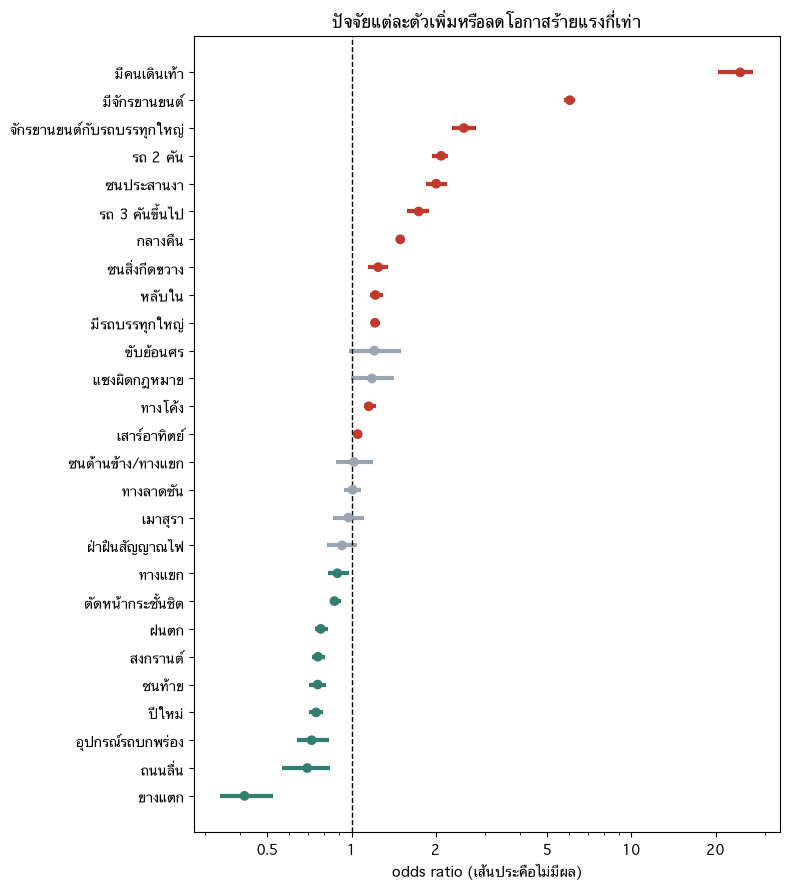

In [39]:
chart = factor_table.iloc[::-1]
colors = []
for result in chart["ผล"]:
    if result == "เพิ่ม":
        colors.append("#c0392b")
    elif result == "ลด":
        colors.append("#327f70")
    else:
        colors.append("#9aa5b1")

fig, ax = plt.subplots(figsize=(8, 9))
ax.hlines(chart.index, chart["ต่ำสุด"], chart["สูงสุด"], color=colors, linewidth=3)
ax.scatter(chart["odds ratio"], chart.index, color=colors, zorder=3)
ax.axvline(1, color="black", linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.set_xticks([0.5, 1, 2, 5, 10, 20])
ax.set_xticklabels(["0.5", "1", "2", "5", "10", "20"])
ax.set(xlabel="odds ratio (เส้นประคือไม่มีผล)", title="ปัจจัยแต่ละตัวเพิ่มหรือลดโอกาสร้ายแรงกี่เท่า")
plt.tight_layout()
plt.show()

**อ่านกราฟ:** จุดคือ odds ratio เส้นคือช่วงความไม่แน่นอน สีแดงคือเพิ่ม สีเขียวคือลด สีเทาคือไม่ชัด

**ปัจจัยที่เพิ่มโอกาสร้ายแรง (12 ตัว)**
- **มีคนเดินเท้า:** odds เพิ่ม 24 เท่า (ช่วง 20–27) สูงที่สุด แต่พบเพียง 1.1% ของเหตุ
- **มีจักรยานยนต์:** 6.0 เท่า (ช่วง 5.8–6.3) และพบถึง 21.4% ของเหตุ
- **จักรยานยนต์กับรถบรรทุกใหญ่:** เพิ่มอีก 2.5 เท่า จากผลของสองปัจจัยนี้รวมกัน
- **รถ 2 คัน** 2.1 เท่า และ **รถ 3 คันขึ้นไป** 1.7 เท่า เทียบกับเหตุรถคันเดียว
- **ชนประสานงา:** 2.0 เท่า เทียบกับพลิกคว่ำหรือตกถนน
- **กลางคืน:** 1.5 เท่า
- **ชนสิ่งกีดขวาง หลับใน มีรถบรรทุกใหญ่ ทางโค้ง:** 1.15–1.25 เท่า
- **เสาร์อาทิตย์:** 1.05 เท่า มีผลจริง แต่น้อยมาก

**ปัจจัยที่มากับเหตุร้ายแรงน้อยลง (9 ตัว)**
- **ยางแตก** (0.41) **ถนนลื่น** (0.69) **อุปกรณ์รถบกพร่อง** (0.72): เหตุกลุ่มนี้มักเป็นรถเสียหลักเอง
- **ฝนตก** (0.78): คำอธิบายที่เป็นไปได้คือคนขับช้าลงตอนฝนตก
- **ปีใหม่** (0.75) และ **สงกรานต์** (0.76): ในตารางข้อ 5.1 ปีใหม่พบในเหตุร้ายแรงมากกว่า (10.9% กับ 6.7%) แต่เมื่อคุมปัจจัยอื่นแล้ว เหตุช่วงเทศกาลกลับร้ายแรงน้อยกว่า เพราะตัวเลขดิบสูงจากจักรยานยนต์ที่มีมากขึ้น
- **ตัดหน้ากระชั้นชิด** (0.87): ตัวเลขดิบสูงกว่า 2.3 เท่า แต่เมื่อคุมแล้วกลับต่ำกว่า 1 เป็น confounding แบบเดียวกัน
- **ชนท้าย** (0.76) และ **ทางแยก** (0.89)

**ปัจจัยที่ยังไม่ชัด (6 ตัว)**
- **เมาสุรา** (0.97 ช่วง 0.86–1.11): ตรงกับที่เห็นในข้อ 4.4
- **ขับย้อนศร** และ **แซงผิดกฎหมาย:** ค่าประมาณ 1.2 แต่พบเพียง 0.4% ของเหตุ ช่วงจึงกว้างและคร่อม 1
- **ชนด้านข้าง/ทางแยก:** สองช่วงปีได้ค่าตรงข้ามกัน (0.80 กับ 1.43) เพราะปี 2023 ใช้ชุดคำต่างจากปีอื่น
- **ทางลาดชัน** และ **ฝ่าฝืนสัญญาณไฟ**

### 10.4 ยิ่งมีปัจจัยเสี่ยงพร้อมกันหลายตัว ยิ่งร้ายแรง
นับว่าแต่ละเหตุมีปัจจัยกลุ่ม "เพิ่ม" กี่ตัว แล้วดูสัดส่วนร้ายแรงจริงของแต่ละกลุ่ม ขั้นนี้นับจากข้อมูลจริง ไม่ได้ใช้ผลทำนายของโมเดล

ปัจจัยกลุ่มเพิ่ม: 12 ตัว
                                       จำนวนเหตุ  สัดส่วนร้ายแรง
จำนวนปัจจัยเสี่ยง (5 คือ 5 ตัวขึ้นไป)                           
0                                          18274           0.078
1                                          45285           0.100
2                                          49346           0.182
3                                          26448           0.297
4                                           8606           0.436
5                                           2138           0.618


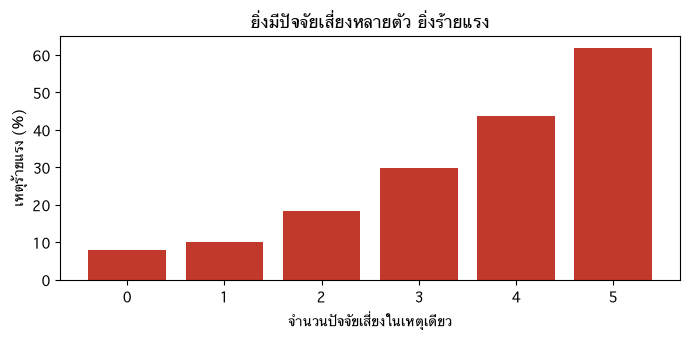

In [40]:
risk_factors = list(factor_table.index[factor_table["ผล"].eq("เพิ่ม")])
print("ปัจจัยกลุ่มเพิ่ม:", len(risk_factors), "ตัว")

# ไม่นับปัจจัยรวม เพราะซ้ำกับ "มีจักรยานยนต์" และ "มีรถบรรทุกใหญ่"
combined_factor = "จักรยานยนต์กับรถบรรทุกใหญ่"
if combined_factor in risk_factors:
    risk_factors.remove(combined_factor)

risk_count = factors[risk_factors].sum(axis=1).clip(upper=5)
by_risk_count = clean.groupby(risk_count)["severe"].agg(["size", "mean"])
by_risk_count.columns = ["จำนวนเหตุ", "สัดส่วนร้ายแรง"]
by_risk_count.index.name = "จำนวนปัจจัยเสี่ยง (5 คือ 5 ตัวขึ้นไป)"
print(by_risk_count.round(3))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(by_risk_count.index, by_risk_count["สัดส่วนร้ายแรง"] * 100, color="#c0392b")
ax.set(xlabel="จำนวนปัจจัยเสี่ยงในเหตุเดียว", ylabel="เหตุร้ายแรง (%)", title="ยิ่งมีปัจจัยเสี่ยงหลายตัว ยิ่งร้ายแรง")
plt.tight_layout()
plt.show()

**อ่านกราฟ:** เหตุที่ไม่มีปัจจัยเสี่ยงเลยร้ายแรง 7.8% เหตุที่มี 2 ตัวร้ายแรง 18.2% มี 4 ตัวร้ายแรง 43.6% และมี 5 ตัวขึ้นไปร้ายแรง 61.8%

เหตุร้ายแรงจึงมักเกิดจากหลายปัจจัยมาซ้อนกัน ไม่ได้เกิดจากปัจจัยเดียว

### 10.5 ตรวจซ้ำด้วยโมเดลอีกแบบ
ถ้าปัจจัยสำคัญจริง โมเดลคนละแบบควรเห็นตรงกัน ขั้นนี้ใช้ **permutation importance** กับ Gradient Boosting บน Test

วิธีคือสลับค่าของคอลัมน์หนึ่งแบบสุ่ม แล้วดูว่า PR-AUC ลดลงเท่าไร ถ้าลดมากแปลว่าโมเดลพึ่งคอลัมน์นั้นมาก

In [41]:
importance = permutation_importance(boosting_model, test_x, test_y, scoring="average_precision",
                                    n_repeats=3, random_state=42)
importance_table = pd.Series(importance.importances_mean, index=model_columns)
importance_table = importance_table.sort_values(ascending=False)
importance_table.head(12).round(3)

มีจักรยานยนต์     0.283
province          0.122
มีคนเดินเท้า      0.083
มีรถบรรทุกใหญ่    0.031
รถ 2 คัน          0.026
road_type         0.018
กลางคืน           0.012
สงกรานต์          0.012
ปีใหม่            0.010
ชนประสานงา        0.009
ชนท้าย            0.006
รถ 3 คันขึ้นไป    0.003
dtype: float64

**อ่านตาราง:** Gradient Boosting พึ่ง `มีจักรยานยนต์` มากที่สุด (PR-AUC ลด 0.283) ตามด้วยจังหวัด (0.122) คนเดินเท้า (0.083) รถบรรทุกใหญ่ (0.031) และรถ 2 คัน (0.026) ตรงกับปัจจัยอันดับต้นของ Logistic Regression โมเดลสองแบบจึงเห็นตรงกัน

อันดับไม่เหมือนกับ odds ratio ทุกตัว เพราะวิธีนี้วัดผลรวม คือขนาดของผลคูณกับจำนวนเหตุที่มีปัจจัยนั้น คนเดินเท้ามี odds ratio สูงสุดแต่พบน้อย จึงอยู่อันดับสาม

**จังหวัดสำคัญเป็นอันดับสอง** ทั้งที่ไม่ได้เป็นปัจจัยที่รายงาน แปลว่าเหตุแบบเดียวกันร้ายแรงไม่เท่ากันในแต่ละจังหวัด ข้อมูลนี้แยกไม่ได้ว่ามาจากความอันตรายจริง หรือมาจากการบันทึกเหตุเล็กน้อยไม่เท่ากัน

## 11. คำตอบส่วนที่ 2: เหตุครั้งนี้ร้ายแรงเพราะอะไร
หัวข้อ 10 ตอบในภาพรวม หัวข้อนี้ตอบเป็นรายเหตุ

**วิธีคิด:** ถามโมเดลว่า "ถ้าเหตุนี้ไม่มีปัจจัยนี้ โอกาสร้ายแรงจะเหลือเท่าไร" ส่วนต่างคือ **แรงผลัก** ของปัจจัยนั้น หน่วยเป็นจุดเปอร์เซ็นต์

ตัวอย่าง: เหตุหนึ่งโมเดลให้ 71% ถ้าเอา "มีจักรยานยนต์" ออกจะเหลือ 15% แรงผลักของจักรยานยนต์คือ +56 จุด

"ไม่มีปัจจัยนี้" หมายถึงเปลี่ยนเป็นกรณีอ้างอิงของปัจจัยนั้น เช่น เอา "กลางคืน" ออกคือเปลี่ยนเป็นกลางวัน

ใช้ `test_model` ที่ฝึกด้วยปี 2020–2024 กับเหตุใน Test เพื่อให้เป็นเหตุที่โมเดลไม่เคยเห็น

In [42]:
# ปัจจัยที่เอาออกทีละตัวได้ คือทุกตัวยกเว้นปัจจัยรวม
single_factors = []
for factor in factor_names:
    if factor != combined_factor:
        single_factors.append(factor)


def predict_without(model, rows, factor):
    changed = rows.copy()
    changed[factor] = 0
    # ปัจจัยรวมต้องคำนวณใหม่ เพราะขึ้นกับสองปัจจัย
    changed[combined_factor] = changed["มีจักรยานยนต์"] * changed["มีรถบรรทุกใหญ่"]
    return model.predict_proba(changed)[:, 1]


def explain_accident(model, one_row):
    probability = model.predict_proba(one_row)[0, 1]
    names = []
    pushes = []
    for factor in single_factors:
        if one_row[factor].iloc[0] == 1:
            probability_without = predict_without(model, one_row, factor)[0]
            names.append(factor)
            pushes.append((probability - probability_without) * 100)
    explanation = pd.DataFrame({"ปัจจัย": names, "แรงผลัก (จุด %)": pushes})
    explanation = explanation.sort_values("แรงผลัก (จุด %)", ascending=False).reset_index(drop=True)
    return probability, explanation

In [43]:
def show_example(title, row_index):
    one_row = test_x.loc[[row_index]]
    probability, explanation = explain_accident(test_model, one_row)
    print(title)
    print("จังหวัด:", one_row["province"].iloc[0], "| ร้ายแรงจริงไหม:", int(test_y.loc[row_index]),
          "| โมเดลให้โอกาสร้ายแรง:", round(probability * 100, 1), "%")
    print(explanation.round(1).to_string(index=False))
    print()


# ตัวอย่างที่ 1: เหตุร้ายแรงที่จักรยานยนต์ชนกับรถบรรทุกใหญ่ตอนกลางคืน
rows_1 = test_x.loc[test_y.eq(1) & test_x[combined_factor].eq(1) & test_x["กลางคืน"].eq(1)]
show_example("ตัวอย่างที่ 1", rows_1.index[0])

# ตัวอย่างที่ 2: เหตุร้ายแรงที่มีคนเดินเท้า
rows_2 = test_x.loc[test_y.eq(1) & test_x["มีคนเดินเท้า"].eq(1)]
show_example("ตัวอย่างที่ 2", rows_2.index[0])

# ตัวอย่างที่ 3: เหตุร้ายแรงที่ไม่มีปัจจัยกลุ่มเพิ่มเลย
rows_3 = test_x.loc[test_y.eq(1) & test_x[risk_factors].sum(axis=1).eq(0)]
show_example("ตัวอย่างที่ 3", rows_3.index[0])

ตัวอย่างที่ 1
จังหวัด: พระนครศรีอยุธยา | ร้ายแรงจริงไหม: 1 | โมเดลให้โอกาสร้ายแรง: 71.4 %
        ปัจจัย  แรงผลัก (จุด %)
 มีจักรยานยนต์             56.3
มีรถบรรทุกใหญ่             24.9
      รถ 2 คัน             18.0
       กลางคืน              9.4
        ปีใหม่             -5.0
        ชนท้าย             -6.3

ตัวอย่างที่ 2
จังหวัด: ตรัง | ร้ายแรงจริงไหม: 1 | โมเดลให้โอกาสร้ายแรง: 88.1 %
       ปัจจัย  แรงผลัก (จุด %)
 มีคนเดินเท้า             62.1
มีจักรยานยนต์             31.3
       ปีใหม่             -2.5

ตัวอย่างที่ 3
จังหวัด: ชลบุรี | ร้ายแรงจริงไหม: 1 | โมเดลให้โอกาสร้ายแรง: 6.1 %
 ปัจจัย  แรงผลัก (จุด %)
เมาสุรา             -0.2
 ปีใหม่             -1.7



**อ่านผล:** - **ตัวอย่างที่ 1:** โมเดลให้ 71.4% ปัจจัยหลักคือมีจักรยานยนต์ (+56.3 จุด) รองลงมาคือมีรถบรรทุกใหญ่ (+24.9) รถ 2 คัน (+18.0) และกลางคืน (+9.4) ส่วนการชนท้ายและช่วงปีใหม่ดึงลงเล็กน้อย
- **ตัวอย่างที่ 2:** โมเดลให้ 88.1% เพราะมีคนเดินเท้า (+62.1) และมีจักรยานยนต์ (+31.3)
- **ตัวอย่างที่ 3:** เหตุนี้ร้ายแรงจริง แต่โมเดลให้เพียง 6.1% เพราะไม่มีปัจจัยเสี่ยงเลย โมเดลจึงอธิบายเหตุนี้ไม่ได้ สิ่งที่ทำให้ร้ายแรงน่าจะเป็นข้อมูลที่ไม่มีในชุดนี้ เช่น ความเร็วจริง

แรงผลักของทุกปัจจัยรวมกันแล้วไม่เท่ากับโอกาสร้ายแรงพอดี เพราะปัจจัยมีผลแบบคูณกัน ไม่ได้บวกกัน ตัวเลขนี้จึงใช้เรียงว่าปัจจัยไหนสำคัญกว่าในเหตุนั้น

### 11.1 เหตุร้ายแรงทั้งหมดใน Test ร้ายแรงเพราะปัจจัยไหนมากที่สุด
คำนวณแรงผลักของทุกปัจจัยให้ทุกเหตุใน Test แล้วหา **ปัจจัยหลัก** ของแต่ละเหตุ คือปัจจัยที่มีแรงผลักมากที่สุด

ถ้าแรงผลักมากที่สุดยังไม่ถึง 2 จุด จะนับว่า "ไม่มีปัจจัยเด่น" คือโมเดลหาเหตุผลจากปัจจัย 27 ตัวนี้ไม่ได้

In [44]:
pushes = pd.DataFrame(index=test_x.index)
for factor in single_factors:
    probability_without = predict_without(test_model, test_x, factor)
    push = test_prob - probability_without
    # เหตุที่ไม่มีปัจจัยนี้ แรงผลักเป็น 0
    push[test_x[factor].values == 0] = 0
    pushes[factor] = push

main_factor = pushes.idxmax(axis=1)
main_push = pushes.max(axis=1)
main_factor.loc[main_push < 0.02] = "ไม่มีปัจจัยเด่น"

severe_main = main_factor.loc[test_y.eq(1)].value_counts(normalize=True) * 100
other_main = main_factor.loc[test_y.eq(0)].value_counts(normalize=True) * 100

main_table = pd.DataFrame({
    "เหตุร้ายแรง (%)": severe_main,
    "เหตุไม่ร้ายแรง (%)": other_main,
}).fillna(0)
main_table = main_table.sort_values("เหตุร้ายแรง (%)", ascending=False)
print("เหตุร้ายแรงใน Test:", int(test_y.sum()), "เหตุ")
main_table.head(10).round(1)

เหตุร้ายแรงใน Test: 7106 เหตุ


,เหตุร้ายแรง (%),เหตุไม่ร้ายแรง (%)
มีจักรยานยนต์,53.5,12.7
รถ 2 คัน,16.3,16.1
ไม่มีปัจจัยเด่น,12.0,44.5
กลางคืน,8.4,18.4
มีคนเดินเท้า,4.8,0.3
รถ 3 คันขึ้นไป,2.2,4.5
หลับใน,1.5,2.3
ชนประสานงา,0.6,0.2
ทางโค้ง,0.4,0.4
ชนสิ่งกีดขวาง,0.2,0.3


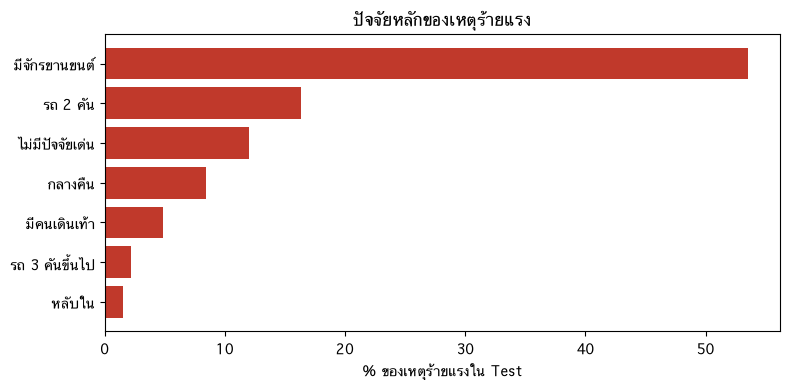

In [45]:
top_main = main_table.head(7).iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(top_main.index, top_main["เหตุร้ายแรง (%)"], color="#c0392b")
ax.set(xlabel="% ของเหตุร้ายแรงใน Test", title="ปัจจัยหลักของเหตุร้ายแรง")
plt.tight_layout()
plt.show()

**อ่านกราฟ:** ในเหตุร้ายแรง 7,106 เหตุ
- **53.5%** มีจักรยานยนต์เป็นปัจจัยหลัก ขณะที่เหตุไม่ร้ายแรงมีเพียง 12.7%
- **16.3%** มีรถ 2 คันเป็นปัจจัยหลัก แต่เหตุไม่ร้ายแรงก็มีสัดส่วนเท่ากัน (16.1%) ปัจจัยนี้อย่างเดียวจึงไม่ได้แยกเหตุร้ายแรงออกมา
- **12.0%** ไม่มีปัจจัยเด่น คือโมเดลอธิบายไม่ได้
- **8.4%** มีกลางคืนเป็นปัจจัยหลัก
- **4.8%** มีคนเดินเท้าเป็นปัจจัยหลัก ขณะที่เหตุไม่ร้ายแรงมีเพียง 0.3%

เหตุร้ายแรงประมาณครึ่งหนึ่งจึงมีจักรยานยนต์เป็นปัจจัยหลัก และประมาณ 1 ใน 8 เป็นเหตุที่ปัจจัยในข้อมูลนี้อธิบายไม่ได้

## 12. บันทึกโมเดล
บันทึก `final_model` ที่ฝึกด้วยข้อมูลทุกปี ตารางปัจจัยถูกบันทึกไปแล้วในหัวข้อ 10.3

In [46]:
model_path = model_dir / "factor_model.joblib"
joblib.dump(final_model, model_path)
print("บันทึกแล้ว:", model_path.relative_to(project_dir))

บันทึกแล้ว: data/explore_idea/severity_factors/model/factor_model.joblib


## 13. สรุป

### สามอย่างที่ต้องมี

| หัวข้อ | คำตอบ |
|---|---|
| **Input feature** | ปัจจัยแบบมีหรือไม่มี 27 ตัว (int 0/1) กับจังหวัดและประเภทถนน (category) ที่ใช้คุมความต่างของพื้นที่ |
| **Model type** | Logistic Regression เพราะให้ตัวเลขหนึ่งตัวต่อหนึ่งปัจจัย |
| **Evaluation metric** | ชั้นที่ 1: PR-AUC, ROC-AUC, Brier score, Calibration บน Test ชั้นที่ 2: odds ratio คงที่ข้ามช่วงปีไหม และช่วงความไม่แน่นอนจาก bootstrap |

### ผลลัพธ์
- **โมเดลเข้ากับความจริงพอใช้:** PR-AUC 0.533 บน Test (เดาสุ่ม 0.169 และ Baseline 0.327) ROC-AUC 0.818 และจับเหตุร้ายแรงได้ 57.1% ที่เกณฑ์ 30%
- **ปัจจัยที่ทำให้ร้ายแรงมากที่สุด:** มีคนเดินเท้า (odds 24 เท่า) มีจักรยานยนต์ (6.0 เท่า) จักรยานยนต์กับรถบรรทุกใหญ่ (เพิ่มอีก 2.5 เท่า) รถ 2 คัน (2.1 เท่า) ชนประสานงา (2.0 เท่า) และกลางคืน (1.5 เท่า)
- **จักรยานยนต์มีผลรวมมากที่สุด:** เพราะทั้งแรงและพบบ่อย เหตุร้ายแรง 53.5% มีจักรยานยนต์เป็นปัจจัยหลัก
- **เหตุร้ายแรงมักมีหลายปัจจัยซ้อนกัน:** เหตุที่ไม่มีปัจจัยเสี่ยงเลยร้ายแรง 7.8% ส่วนเหตุที่มี 5 ตัวขึ้นไปร้ายแรง 61.8%
- **ตัวเลขดิบหลอกตา:** เมาสุราและช่วงเทศกาลดูร้ายแรงสูง แต่เมื่อคุมปัจจัยอื่นแล้ว เมาสุราไม่ชัด และช่วงเทศกาลกลับร้ายแรงน้อยกว่า
- **สรุปทิศทางได้ 21 จาก 27 ปัจจัย:** เพิ่ม 12 ตัว ลด 9 ตัว และยังไม่ชัด 6 ตัว
- **โมเดลสองแบบเห็นตรงกัน:** Gradient Boosting ให้ปัจจัยอันดับต้นตรงกับ Logistic Regression
- **อธิบายไม่ได้ทุกเหตุ:** เหตุร้ายแรง 12.0% ไม่มีปัจจัยเด่นจากข้อมูลนี้

### ข้อจำกัด
- **เป็นความสัมพันธ์ ไม่ใช่การพิสูจน์สาเหตุ:** โมเดลคุมได้เฉพาะสิ่งที่มีในข้อมูล ข้อมูลนี้ไม่มีความเร็วจริง การสวมหมวกกันน็อก และการคาดเข็มขัดนิรภัย
- **มูลเหตุเป็นการสันนิษฐาน:** เจ้าหน้าที่บันทึกหลังเกิดเหตุ และ 71% ถูกบันทึกว่าขับรถเร็ว
- **พื้นที่ยังมีผลมาก:** จังหวัดเป็นคอลัมน์ที่โมเดลพึ่งมากเป็นอันดับสอง แต่แยกไม่ได้ว่ามาจากความอันตรายจริงหรือวิธีบันทึกที่ต่างกัน
- **แรงผลักรายเหตุมาจากโมเดล:** เป็นการถามโมเดลว่าถ้าไม่มีปัจจัยนี้จะเป็นอย่างไร ไม่ได้เกิดจากการทดลองจริง
- **หมวดหมู่ไม่เหมือนกันทุกปี:** ปี 2023 ใช้ชุดคำของลักษณะการชนต่างจากปีอื่น ปัจจัยกลุ่ม "ชนกันแบบไหน" จึงควรอ่านอย่างระวัง